In [1]:
import pandas as pd

from gridforecast.config import TEST_END, TEST_START
from gridforecast.data.store import load
from gridforecast.evaluation import metrics
from gridforecast.evaluation.backtest import rolling_origin_backtest
from gridforecast.pipeline.tables import ORIGINS


class LastWeek:
    def fit(self, X, y):
        return self

    def predict(self, X):
        point = X["lag_7d"]
        return pd.DataFrame({"q10": point * 0.95, "q50": point, "q90": point * 1.05})


origins = load(ORIGINS)
preds = rolling_origin_backtest(LastWeek, origins, TEST_START, TEST_END)
print(metrics.score(preds))
metrics.score_by(preds, "fold")[["mae", "mape", "coverage_80"]].round(2)

2025-11: trained on 167,376 rows, forecast 2,880
2025-12: trained on 170,256 rows, forecast 2,976
2026-01: trained on 173,232 rows, forecast 2,976
2026-02: trained on 176,208 rows, forecast 2,688
2026-03: trained on 178,896 rows, forecast 2,972
2026-04: trained on 181,872 rows, forecast 2,880
2026-05: trained on 184,752 rows, forecast 2,976
2026-06: trained on 187,728 rows, forecast 2,880
2026-07: trained on 190,608 rows, forecast 2,976
2026-08: trained on 193,584 rows, forecast 2,976
2026-09: trained on 196,560 rows, forecast 2,880
2026-10: trained on 199,440 rows, forecast 2,980
{'mae': 2151.9808789954336, 'mape': 8.47840094555332, 'rmse': 2936.2383793903764, 'pinball': 822.6880389079146, 'coverage_80': 0.41983447488584474, 'below_q10': 0.2896689497716895, 'above_q90': 0.29049657534246576, 'width_80': 2605.5126141552532, 'n': 35040}


,mae,mape,coverage_80
2025-11,2412.31,7.94,0.39
2025-12,2300.14,7.77,0.38
2026-01,2980.14,8.91,0.33
2026-02,2137.71,7.31,0.50
2026-03,2233.54,8.41,0.39
2026-04,2494.90,11.40,0.38
2026-05,1897.76,8.84,0.48
2026-06,2020.56,9.24,0.35
2026-07,1593.79,7.61,0.49
2026-08,1750.34,7.96,0.49


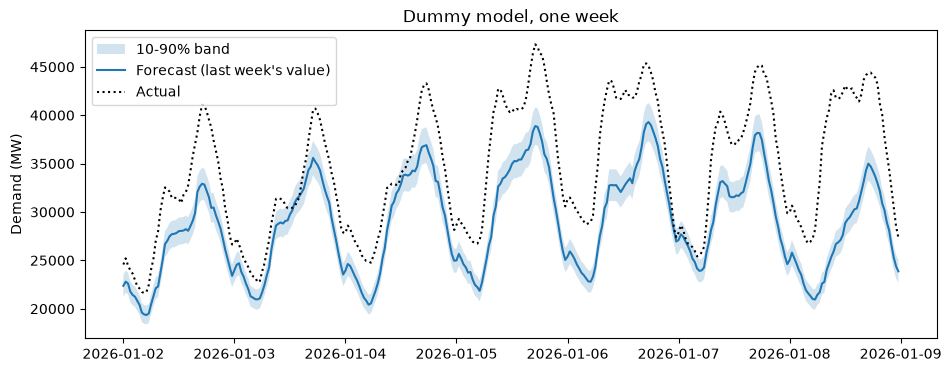

In [2]:
import matplotlib.pyplot as plt

from gridforecast.config import UK

week = preds[(preds["lead_day"] == 1) & (preds["fold"] == "2026-01")].head(7 * 48)
x = week["target_time"].dt.tz_convert(UK).dt.tz_localize(None)  # matplotlib wants naive times
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(x, week["q10"], week["q90"], alpha=0.2, label="10-90% band")
ax.plot(x, week["q50"], label="Forecast (last week's value)")
ax.plot(x, week["indo_mw"], color="black", ls=":", label="Actual")
ax.set(ylabel="Demand (MW)", title="Dummy model, one week")
ax.legend()